# Building Perceptron

## Introduction

**Contexte.** Le Perceptron, proposé par Frank Rosenblatt en 1958, est le premier neurone artificiel capable d'apprendre. Il classe des données en deux catégories en traçant une frontière linéaire.

**Objectif.** Développer un Perceptron en Python (programmation orientée objet), vérifier son fonctionnement sur des données factices, puis l'appliquer au jeu de données *Breast Cancer Wisconsin* pour prédire si une tumeur est bénigne ou maligne.

**Plan du notebook.**
1. Développement du Perceptron et test sur données factices
2. Récupération des données
3. Nettoyage et analyse exploratoire
4. Réduction de dimensionnalité
5. Modélisation avec le Perceptron
6. Évaluation
7. Conclusion

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from script import Perceptron

## 1. Développement du Perceptron et test sur données factices

La classe `Perceptron` est définie dans le fichier `script.py`. Elle contient :
- `fit(X, y)` : entraînement avec la règle du perceptron, w ← w + η (y − ŷ) x ;
- `predict(X)` : prédiction 0 ou 1 grâce à la fonction de Heaviside ;
- `score(X, y)` : proportion de bonnes prédictions (accuracy).

Avant de l'utiliser sur des données réelles, on vérifie qu'elle fonctionne sur des données factices dont on connaît la solution.

### 1.1 Génération de données factices

On génère aléatoirement 200 points en 2 dimensions, répartis en deux groupes :
- classe 0 : 100 points centrés autour de (−2, −2) ;
- classe 1 : 100 points centrés autour de (2, 2).

Les deux groupes sont bien séparés : une droite doit pouvoir les distinguer.

In [2]:
rng = np.random.default_rng(42)

n = 100
X_classe0 = rng.normal(loc=-2, scale=1, size=(n, 2))
X_classe1 = rng.normal(loc=2, scale=1, size=(n, 2))

X_fake = np.vstack([X_classe0, X_classe1])
y_fake = np.array([0] * n + [1] * n)

print("Dimensions de X :", X_fake.shape)
print("Répartition des classes :", np.bincount(y_fake))

Dimensions de X : (200, 2)
Répartition des classes : [100 100]


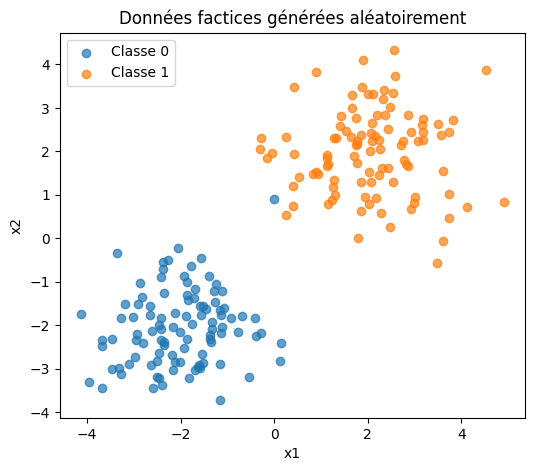

In [3]:
plt.figure(figsize=(6, 5))
plt.scatter(X_classe0[:, 0], X_classe0[:, 1], label="Classe 0", alpha=0.7)
plt.scatter(X_classe1[:, 0], X_classe1[:, 1], label="Classe 1", alpha=0.7)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Données factices générées aléatoirement")
plt.legend()
plt.show()

**Interprétation.** Les deux nuages de points sont distincts et ne se chevauchent presque pas : les données sont linéairement séparables. D'après le théorème de convergence, le Perceptron doit trouver une frontière qui les sépare.

### 1.2 Séparation entraînement / test

On garde 20 % des points pour tester le modèle sur des données qu'il n'a jamais vues.

In [4]:
indices = rng.permutation(len(X_fake))
split = int(0.8 * len(X_fake))
train_idx, test_idx = indices[:split], indices[split:]

X_train_fake, X_test_fake = X_fake[train_idx], X_fake[test_idx]
y_train_fake, y_test_fake = y_fake[train_idx], y_fake[test_idx]

print("Entraînement :", X_train_fake.shape[0], "points")
print("Test :", X_test_fake.shape[0], "points")

Entraînement : 160 points
Test : 40 points


### 1.3 Entraînement

In [5]:
perceptron_fake = Perceptron(learning_rate=0.1, n_epochs=50)
perceptron_fake.fit(X_train_fake, y_train_fake)

print("Poids appris (w) :", perceptron_fake.weights)
print("Biais appris (b) :", perceptron_fake.bias)
print("Nombre d'epochs effectuées :", len(perceptron_fake.errors_))

Poids appris (w) : [0.4476767  0.21666749]
Biais appris (b) : -0.20000000000000004
Nombre d'epochs effectuées : 20


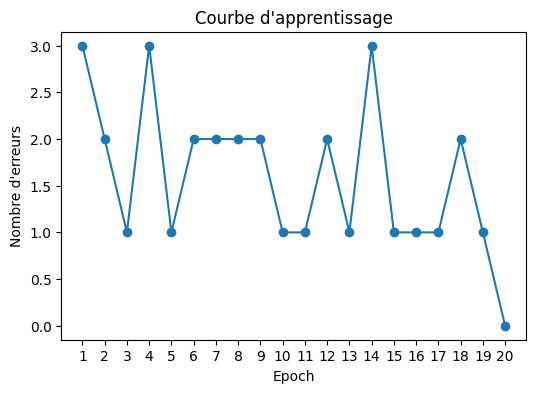

In [6]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(perceptron_fake.errors_) + 1), perceptron_fake.errors_, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Nombre d'erreurs")
plt.title("Courbe d'apprentissage")
plt.xticks(range(1, len(perceptron_fake.errors_) + 1))
plt.show()

**Interprétation.** Le nombre d'erreurs diminue jusqu'à zéro : le Perceptron a convergé et s'est arrêté avant d'atteindre le nombre maximal d'epochs. C'est le comportement attendu sur des données linéairement séparables.

### 1.4 Frontière de décision

La frontière apprise est la droite d'équation w1·x1 + w2·x2 + b = 0, soit x2 = −(w1·x1 + b) / w2.

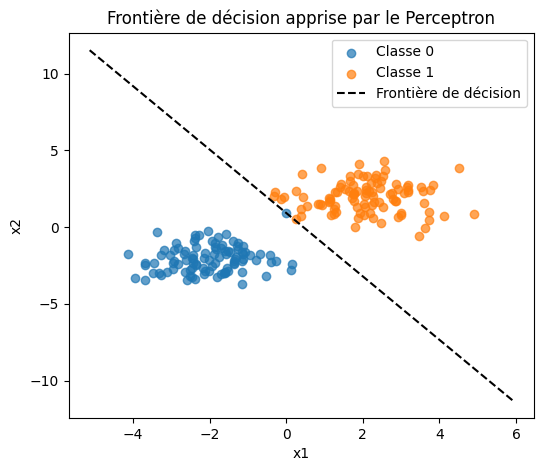

In [7]:
w1, w2 = perceptron_fake.weights
b = perceptron_fake.bias

x1_vals = np.linspace(X_fake[:, 0].min() - 1, X_fake[:, 0].max() + 1, 100)
x2_vals = -(w1 * x1_vals + b) / w2

plt.figure(figsize=(6, 5))
plt.scatter(X_classe0[:, 0], X_classe0[:, 1], label="Classe 0", alpha=0.7)
plt.scatter(X_classe1[:, 0], X_classe1[:, 1], label="Classe 1", alpha=0.7)
plt.plot(x1_vals, x2_vals, "k--", label="Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Frontière de décision apprise par le Perceptron")
plt.legend()
plt.show()

**Interprétation.** La droite apprise sépare correctement les deux groupes. Elle ne passe pas forcément « au milieu » : le Perceptron s'arrête dès qu'il trouve une frontière sans erreur, pas la meilleure possible.

### 1.5 Évaluation sur le jeu de test

In [8]:
print(f"Accuracy entraînement : {perceptron_fake.score(X_train_fake, y_train_fake):.2%}")
print(f"Accuracy test : {perceptron_fake.score(X_test_fake, y_test_fake):.2%}")

Accuracy entraînement : 100.00%
Accuracy test : 100.00%


**Conclusion de la partie 1.** Le Perceptron classe correctement des points qu'il n'a jamais vus. La classe fonctionne : on peut l'appliquer à des données réelles.

## 2. Récupération des données

Le jeu de données *Breast Cancer Wisconsin (Diagnostic)* provient de l'UCI Machine Learning Repository (Wolberg, Street et Mangasarian, 1995), téléchargé depuis Kaggle.

Chaque ligne décrit une tumeur du sein à partir d'une image numérisée d'une ponction à l'aiguille fine (cytoponction). Dix caractéristiques des noyaux cellulaires sont mesurées (rayon, texture, périmètre, aire, lissage, compacité, concavité, points concaves, symétrie, dimension fractale), chacune résumée de trois façons :
- `_mean` : moyenne sur les noyaux de l'image ;
- `_se` : erreur standard (variabilité) ;
- `_worst` : moyenne des trois valeurs les plus élevées.

La variable cible `diagnosis` vaut **M** (malin) ou **B** (bénin).

In [9]:
df = pd.read_csv("data/data.csv")

print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

**Observation.** 569 tumeurs et 33 colonnes : un identifiant `id`, la cible `diagnosis`, 30 mesures numériques, et une colonne `Unnamed: 32` qui semble vide.

## 3. Nettoyage et analyse exploratoire

### 3.1 Vérifications de qualité

In [11]:
print("Valeurs manquantes par colonne (colonnes concernées) :")
valeurs_manquantes = df.isna().sum()
print(valeurs_manquantes[valeurs_manquantes > 0])

print("\nLignes dupliquées :", df.duplicated().sum())
print("Identifiants dupliqués :", df["id"].duplicated().sum())

Valeurs manquantes par colonne (colonnes concernées) :
Unnamed: 32    569
dtype: int64

Lignes dupliquées : 0
Identifiants dupliqués : 0


**Interprétation.**
- La colonne `Unnamed: 32` est entièrement vide (569 valeurs manquantes sur 569) : c'est un artefact d'export du fichier CSV, elle ne contient aucune information.
- Aucune autre colonne ne contient de valeur manquante.
- Aucun doublon : chaque ligne correspond à une tumeur différente.

### 3.2 Nettoyage

Trois corrections sont nécessaires :
1. **Supprimer `Unnamed: 32`** : colonne vide.
2. **Supprimer `id`** : simple numéro de patient, sans valeur prédictive. Le garder risquerait de faire apprendre du bruit au modèle.
3. **Encoder `diagnosis`** en 0/1, car le Perceptron travaille avec des nombres : **M = 1** (malin, la classe que l'on cherche à détecter), **B = 0** (bénin).

In [12]:
df_clean = df.drop(columns=["id", "Unnamed: 32"])
df_clean["diagnosis"] = df_clean["diagnosis"].map({"M": 1, "B": 0})

print("Dimensions après nettoyage :", df_clean.shape)
print("Valeurs manquantes restantes :", df_clean.isna().sum().sum())
df_clean.head()

Dimensions après nettoyage : (569, 31)
Valeurs manquantes restantes : 0


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [13]:
features = df_clean.drop(columns="diagnosis")

print("Valeurs négatives :", (features < 0).sum().sum())
print("\nColonnes contenant des zéros :")
zeros = (features == 0).sum()
print(zeros[zeros > 0])

Valeurs négatives : 0

Colonnes contenant des zéros :
concavity_mean          13
concave points_mean     13
concavity_se            13
concave points_se       13
concavity_worst         13
concave points_worst    13
dtype: int64


**Interprétation.**
- Aucune valeur négative : cohérent, ce sont des tailles et des formes.
- 13 tumeurs ont une valeur nulle dans les 6 colonnes de concavité. Ce ne sont **pas des données manquantes** : un contour parfaitement lisse n'a aucune concavité. Ces valeurs sont donc conservées.

### 3.3 Statistiques descriptives

In [14]:
features.describe().T

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


**Interprétation.** Les variables ont des échelles très différentes : `area_mean` dépasse 2 500 alors que `smoothness_mean` reste inférieur à 0,2. Le Perceptron calcule une somme pondérée : sans mise à l'échelle, les variables à grandes valeurs domineraient les autres. Une **standardisation** sera donc nécessaire avant la modélisation.

### 3.4 Répartition de la variable cible

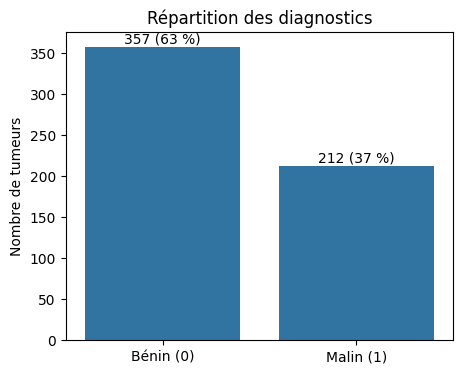

In [15]:
repartition = df_clean["diagnosis"].value_counts().sort_index()
pourcentages = df_clean["diagnosis"].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(5, 4))
ax = sns.countplot(x="diagnosis", data=df_clean)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Bénin (0)", "Malin (1)"])
for i, (n, p) in enumerate(zip(repartition, pourcentages)):
    ax.text(i, n + 5, f"{n} ({p:.0f} %)", ha="center")
plt.title("Répartition des diagnostics")
plt.ylabel("Nombre de tumeurs")
plt.xlabel("")
plt.show()

**Interprétation.** 357 tumeurs bénignes (63 %) contre 212 malignes (37 %) : les classes sont légèrement déséquilibrées. Un modèle qui prédirait toujours « bénin » obtiendrait déjà 63 % d'accuracy. L'accuracy seule ne suffira donc pas : il faudra regarder le **rappel** sur la classe maligne (proportion de cancers détectés).

### 3.5 Distribution des variables selon le diagnostic

On compare la distribution des 10 variables `_mean` entre tumeurs bénignes et malignes.

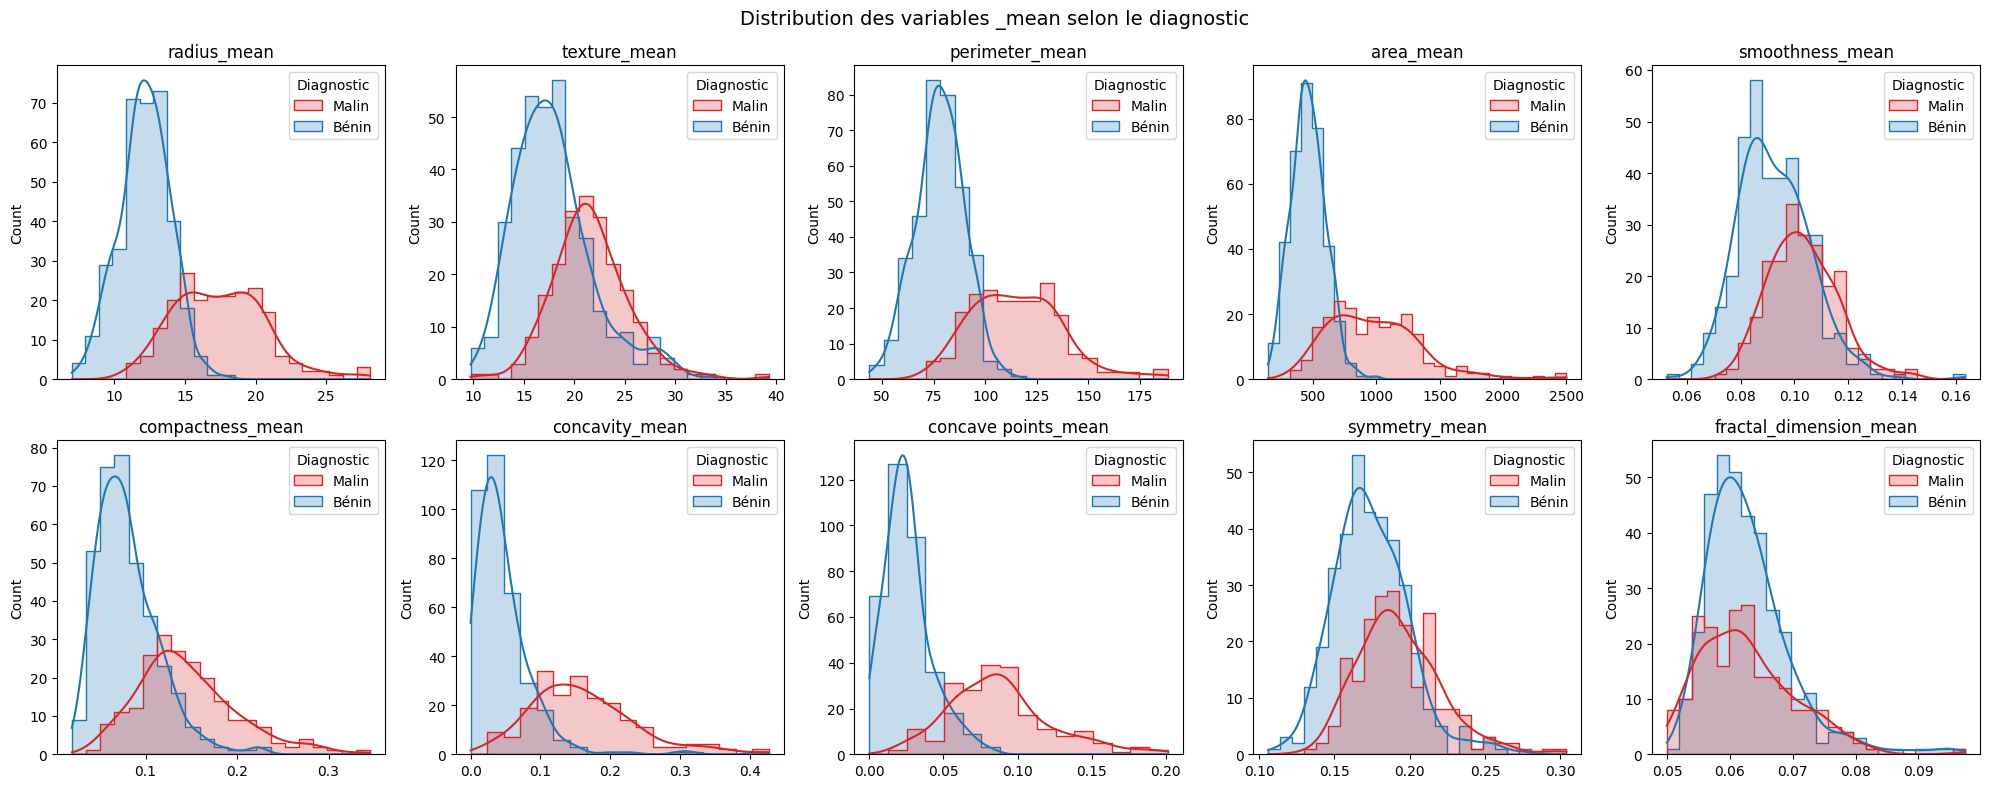

In [16]:
mean_cols = [c for c in features.columns if c.endswith("_mean")]

# Colonne texte uniquement pour des légendes lisibles dans les graphiques
df_plot = df_clean.assign(Diagnostic=df_clean["diagnosis"].map({0: "Bénin", 1: "Malin"}))
couleurs = {"Bénin": "tab:blue", "Malin": "tab:red"}

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.flatten(), mean_cols):
    sns.histplot(data=df_plot, x=col, hue="Diagnostic", kde=True, ax=ax,
                 palette=couleurs, element="step")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distribution des variables _mean selon le diagnostic", fontsize=14)
plt.tight_layout()
plt.show()

**Interprétation.**
- Les variables de **taille** (`radius`, `perimeter`, `area`) et de **concavité** (`concavity`, `concave points`) séparent nettement les deux classes : les tumeurs malignes sont plus grosses et ont un contour plus irrégulier.
- `texture_mean` sépare un peu moins bien, les deux distributions se chevauchent.
- `fractal_dimension_mean`, `smoothness_mean` et `symmetry_mean` se chevauchent fortement : elles distinguent mal les deux classes.

### 3.6 Valeurs extrêmes

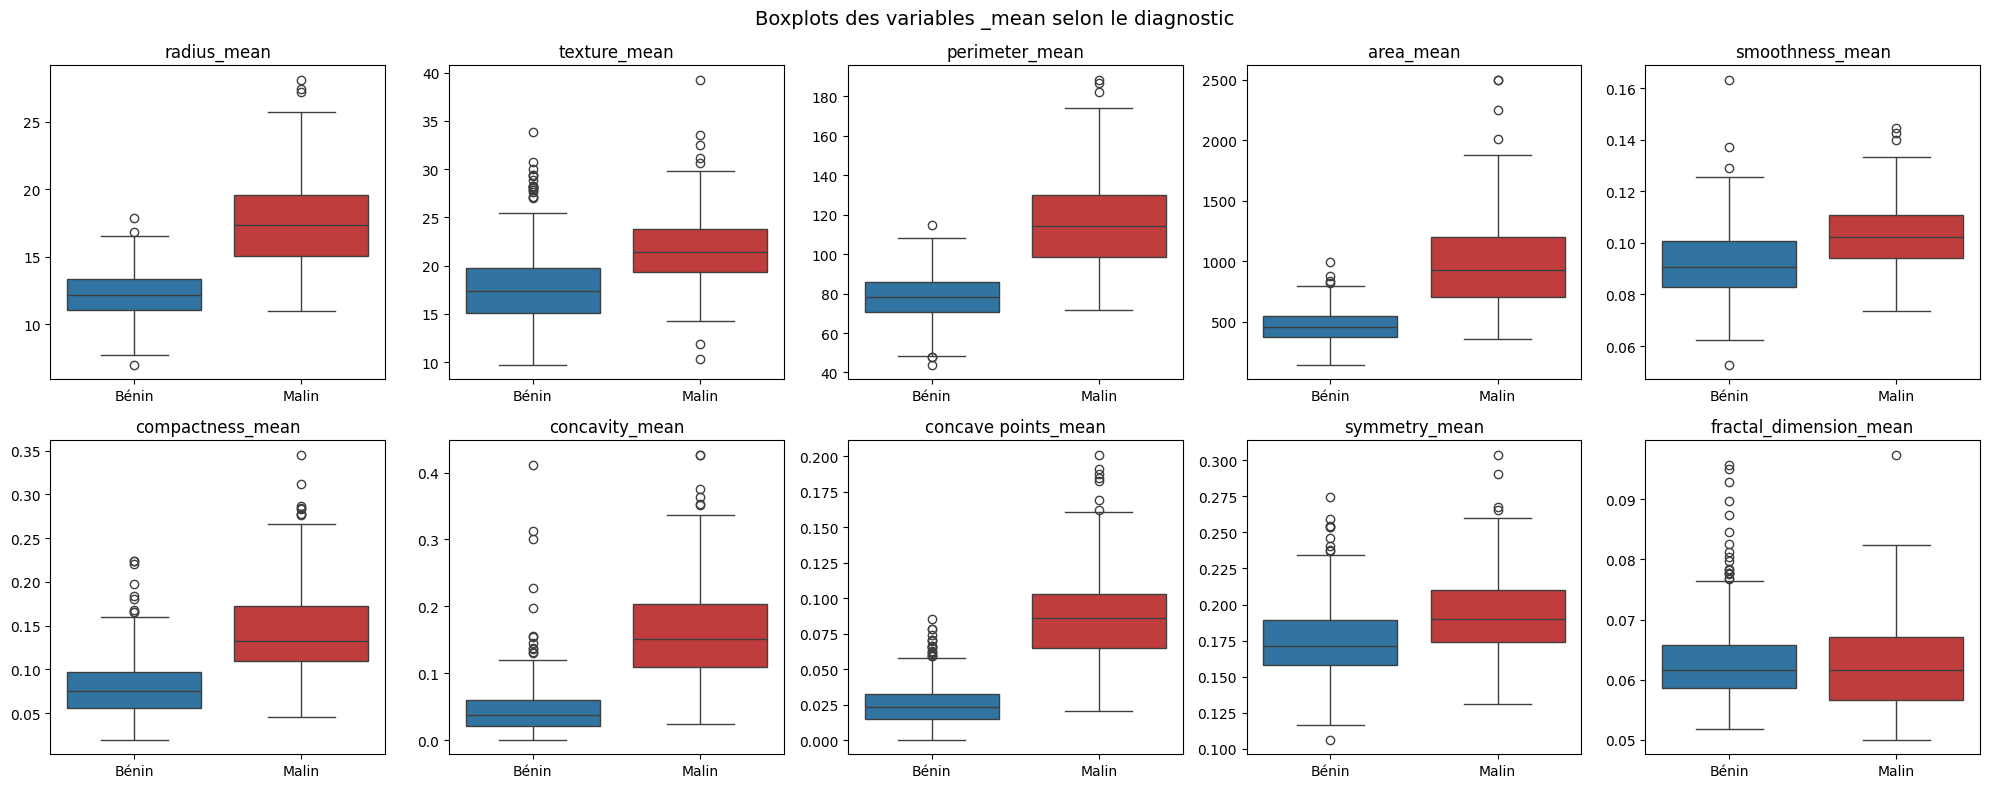

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.flatten(), mean_cols):
    sns.boxplot(data=df_plot, x="Diagnostic", y=col, ax=ax, order=["Bénin", "Malin"],
                palette=couleurs, hue="Diagnostic", legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Boxplots des variables _mean selon le diagnostic", fontsize=14)
plt.tight_layout()
plt.show()

In [18]:
q1 = features.quantile(0.25)
q3 = features.quantile(0.75)
iqr = q3 - q1
outliers = (features < q1 - 1.5 * iqr) | (features > q3 + 1.5 * iqr)

print("Tumeurs avec au moins une valeur extrême :", outliers.any(axis=1).sum(), "sur", len(features))
print("\nVariables les plus concernées :")
print(outliers.sum().sort_values(ascending=False).head(5))

Tumeurs avec au moins une valeur extrême : 171 sur 569

Variables les plus concernées :
area_se          65
radius_se        38
perimeter_se     38
area_worst       35
smoothness_se    30
dtype: int64


**Interprétation.** 171 tumeurs sur 569 présentent au moins une valeur extrême selon la règle de l'écart interquartile, surtout sur les variables `_se`. Ces valeurs ne sont **pas des erreurs de mesure** : elles correspondent souvent à de grosses tumeurs malignes, justement celles que l'on veut détecter. Les supprimer ferait perdre près d'un tiers des données et des cas les plus informatifs. Elles sont donc **conservées** ; la standardisation limitera leur influence sur l'échelle.

### 3.7 Corrélations

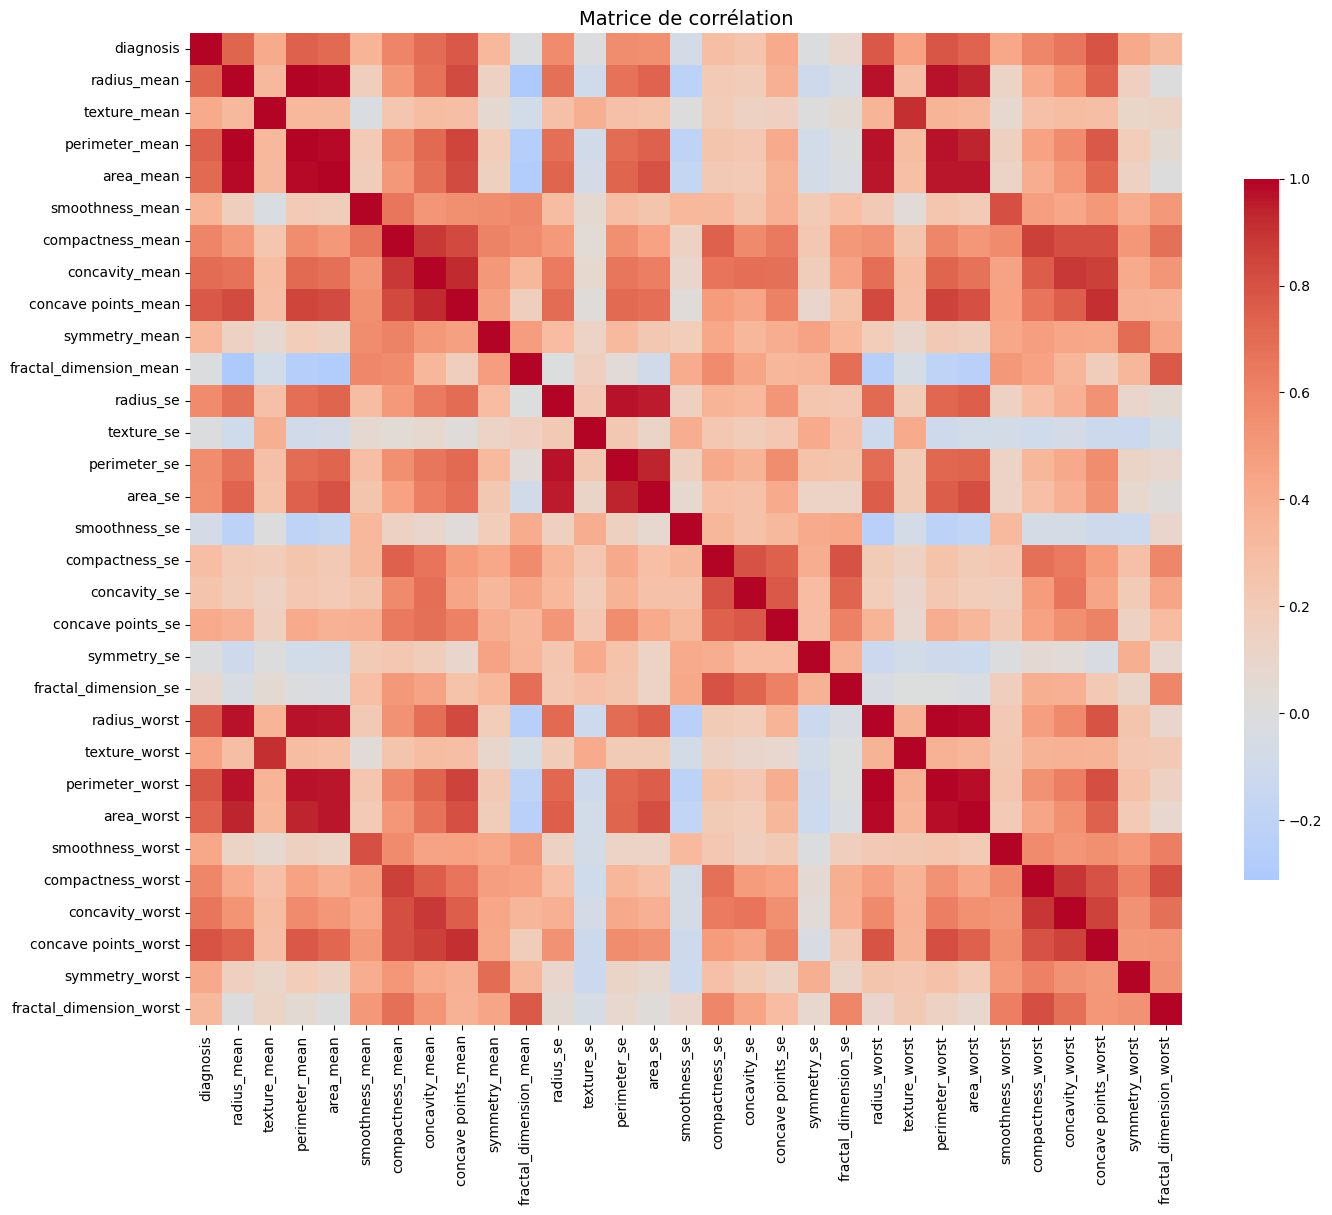

In [19]:
plt.figure(figsize=(16, 13))
sns.heatmap(df_clean.corr(), cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.7})
plt.title("Matrice de corrélation", fontsize=14)
plt.show()

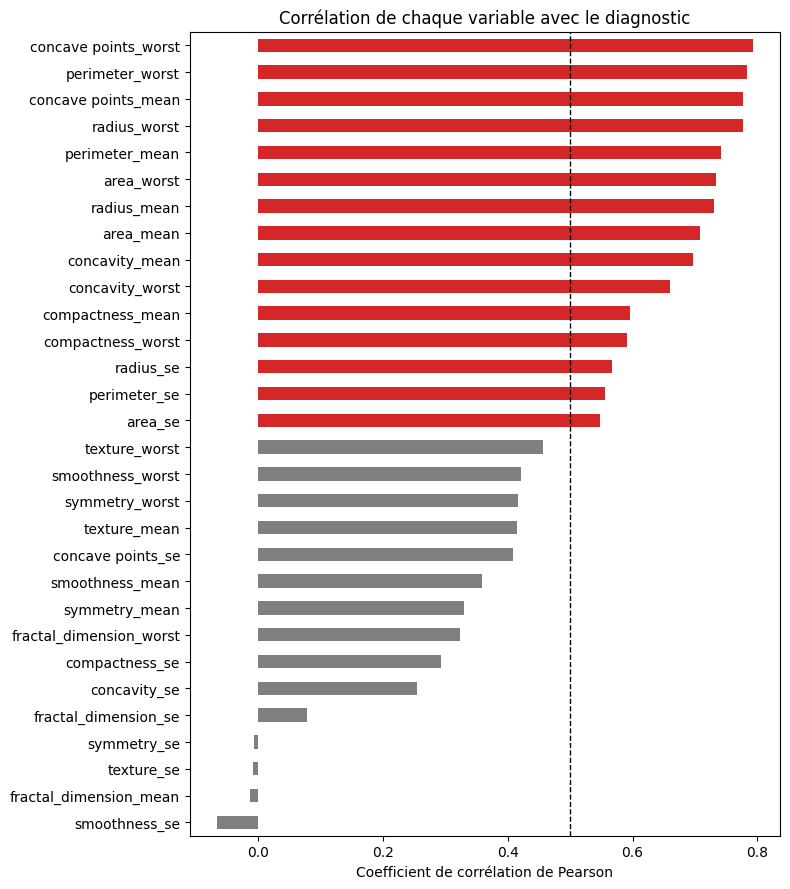

In [20]:
corr_cible = df_clean.corr()["diagnosis"].drop("diagnosis").sort_values()

plt.figure(figsize=(8, 9))
corr_cible.plot(kind="barh", color=["tab:red" if v > 0.5 else "tab:gray" for v in corr_cible])
plt.axvline(0.5, color="black", linestyle="--", linewidth=1)
plt.title("Corrélation de chaque variable avec le diagnostic")
plt.xlabel("Coefficient de corrélation de Pearson")
plt.tight_layout()
plt.show()

In [21]:
corr_abs = features.corr().abs()
paires = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool)).stack()
paires = paires.sort_values(ascending=False)

print("Paires de variables corrélées à plus de 0,9 :", (paires > 0.9).sum())
paires.head(8)

Paires de variables corrélées à plus de 0,9 : 21


radius_mean      perimeter_mean     0.997855
radius_worst     perimeter_worst    0.993708
radius_mean      area_mean          0.987357
perimeter_mean   area_mean          0.986507
radius_worst     area_worst         0.984015
perimeter_worst  area_worst         0.977578
radius_se        perimeter_se       0.972794
perimeter_mean   perimeter_worst    0.970387
dtype: float64

**Interprétation.**
- **Lien avec le diagnostic :** les variables les plus corrélées au caractère malin sont `concave points_worst` (0,79), `perimeter_worst` (0,78), `concave points_mean` (0,78) et `radius_worst` (0,78). Taille et irrégularité du contour sont les meilleurs indicateurs.
- **Redondance :** 21 paires de variables sont corrélées à plus de 0,9. Par exemple `radius_mean` et `perimeter_mean` (0,998) : c'est logique, le périmètre d'un cercle vaut 2πr. Ces variables apportent quasiment la même information.

Cette forte redondance justifie la **réduction de dimensionnalité** de l'étape suivante.

### 3.8 Synthèse de l'analyse exploratoire

| Constat | Conséquence pour la suite |
|---|---|
| Données complètes après suppression de `id` et `Unnamed: 32` | Pas d'imputation nécessaire |
| Échelles très différentes | Standardisation obligatoire |
| Classes déséquilibrées (63 % / 37 %) | Évaluer avec le rappel et le F1, pas seulement l'accuracy |
| Taille et concavité séparent bien les classes | Le Perceptron a de bonnes chances de réussir |
| Forte redondance entre variables | Réduction de dimensionnalité |
| Valeurs extrêmes réelles et informatives | Conservées |